In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate

In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [34]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [4]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [5]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [6]:
import astropy.units as u
from astropy.modeling.models import Moffat1D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat1D.html
from astropy.modeling.functional_models import Moffat2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat2D.html


In [242]:
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import PchipInterpolator
from tqdm.auto import tqdm
import math

In [8]:
def Moffat_1d_profile(amplitude, x_0, gamma, alpha): 
    """
    Returns a 1D Moffat profile function.
    
    Parameters:
    amplitude : float
        The peak value of the profile.
    x_0 : float
        The position of the peak.
    gamma : float
        The scale parameter, related to the FWHM.
    alpha : float
        The shape parameter, controlling the wings of the profile.
    
    Returns:
    function
        A function that computes the Moffat profile at given x values.
    """
    def profile(x):
        return amplitude * (1 + ((x - x_0) / gamma) ** 2) ** (-alpha)
    
    return profile

### Point source coupling jitter effect

In [12]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / 206265 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [9]:
def radial_to_eta_map(
        eta_psf_interp,
        decentre_array: np.ndarray,
        x: np.ndarray,
        y: np.ndarray
) -> np.ndarray:
    """
    Convert a radial point-source coupling efficiency function
    into a 2D coupling efficiency map.
    """

    # Calculate the radial distance from the fibre centre.
    r_grid = np.sqrt(x**2 + y**2)

    # Create an empty array for the 2D coupling map.
    eta_map_2d = np.zeros_like(r_grid)

    # Select positions covered by the calculated radial response.
    inside_range = r_grid <= decentre_array[-1]

    # Interpolate the radial coupling efficiency onto the 2D grid.
    eta_map_2d[inside_range] = eta_psf_interp(
        r_grid[inside_range]
    )

    return eta_map_2d

In [10]:
def generate_jitter_positions(
    sigma_jitter_rms_mas: float,
    focal_length: float,
    demagnification: float,
    n_samples: int,
    rng: np.random.Generator
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate random x and y tip-tilt jitter displacements at the fibre plane. 
    The displacements are drawn from a normal distribution with mean 0 and standard deviation corresponding to 
    the RMS jitter specified in milliarcseconds.
    This is a helper function to generate random jitter positions for Monte Carlo simulations of coupling efficiency.

    Parameters
    ----------
    sigma_jitter_rms_mas:
        RMS jitter in milliarcseconds.

    focal_length:
        Telescope focal length in metres.

    demagnification:
        Demagnification factor between the telescope focal plane
        and the fibre plane.

    n_samples:
        Number of random jitter positions.

    rng:
        NumPy random number generator.

    Returns
    -------
    delta_x, delta_y:
        Random x and y jitter displacements at the fibre plane, in metres.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane.
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_rms_mas,
        focal_length,
        demagnification
    )

    # Generate random x jitter positions.
    delta_x = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    # Generate random y jitter positions.
    delta_y = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    return delta_x, delta_y

In [27]:
def Monte_Carlo_point_source_coupling(
    x, y, 
    x_1d, y_1d,
    delta_x, delta_y, 
    eta_map_fixed: np.ndarray,
    acceptance_radius=None,
    fibre_x=0.0,
    fibre_y=0.0,
):
    """
    Perform a Monte Carlo simulation to calculate the coupling efficiency
    of a point source in the presence of tip-tilt jitter.

    For each random jitter position, the point source position is evaluated
    on the fixed 2D coupling efficiency map.

    Parameters
    ----------
    x_1d : 1D array of x-coordinates at the fibre plane, in metres.

    y_1d : 1D array of y-coordinates at the fibre plane, in metres.

    delta_x : Random x-direction jitter displacements at the fibre plane, in metres.

    delta_y : Random y-direction jitter displacements at the fibre plane, in metres.

    eta_map_fixed : np.ndarray
        Fixed 2D point-source coupling efficiency map.

    acceptance_radius : float or None
        Radius of the circular acceptance region, in metres.

        If None, no additional circular acceptance boundary is applied.

        If a radius is given, coupling is set to zero when the point
        source is outside this radius.

    fibre_x : float
        Fixed x-position of the fibre centre, in metres.

    fibre_y : float
        Fixed y-position of the fibre centre, in metres.

    Returns
    -------
    eta_samples : np.ndarray
        Coupling efficiency for each Monte Carlo jitter position.
    """

    # Number of Monte Carlo samples determined by the number of jitter positions provided.
    n_samples = len(delta_x)

    # Create an empty array in which to store the coupling efficiency for each jitter position.
    eta_samples = np.zeros(n_samples)


    # Apply a circular acceptance boundary if one is specified.
    if acceptance_radius is not None:

        # Mask the 2D coupling efficiency map to only include points within the acceptance radius.
        acceptance_mask = (
            np.sqrt(
                (x - fibre_x)**2
                + (y - fibre_y)**2
            )
            <= acceptance_radius
        )
        
        eta_map_fixed = eta_map_fixed.copy() 
        eta_map_fixed[~acceptance_mask] = 0.0

        # # Calculate the radial position of each point source.
        # radial_displacement = np.sqrt(
        #     delta_x**2 + delta_y**2
        # )

    for i in range(n_samples):
        # Calculate the shifted position (in physical units) of th point source due to jitter.
        dx_metre = delta_x[i]
        dy_metre = delta_y[i]

        # Find the closest x-grid position to the jittered point source, x_1d - dx_metre is 1d array minus a scalar, 
        # so the result is a 1d array of the same length as x_1d. np.abs gives the absolute value of each element in that array, 
        # and np.argmin returns the index of the minimum value in that array. This index corresponds to the closest x-grid position 
        # to the jittered point source.
        x_index = np.argmin(np.abs(x_1d - dx_metre)) 

        # Find the closest y-grid position to the jittered point source
        y_index = np.argmin(np.abs(y_1d - dy_metre))

        # Evaluate the coupling efficiency at the shifted position.
        eta_samples[i] = eta_map_fixed[y_index, x_index]

    return eta_samples

In [18]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# numerical aperture of fibre
NA = 0.1 

# # Calculate the normalised frequency (V-number) of the fibre
# V = 2 * pi * (a / lam0) * NA
# print(f"V-number of the fibre: {V:.2f}")

In [24]:
f_coude = 399
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9
D_M1 = 8.0
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [17]:
r_max = 125e-6  # maximum radial distance from the fibre centre, in metres
x_1d = np.linspace(-r_max, r_max, 1000) # x-coordinates at the fibre plane, in metres
y_1d = np.linspace(-r_max, r_max, 1000) # y-coordinates at the fibre plane, in metres
x, y = np.meshgrid(x_1d, y_1d)

In [20]:
# Only test for a single normalised frequency at r=5.7microns for my first test of decentred position
prepared_smf_mode_5p7micron = prepare_modes_2d(
                                x, y,
                                a=5.7e-6, 
                                NA=NA, 
                                lam0=lam0, 
                                az_sym=True, 
                                mode_case="few_mode"
                            )

In [22]:
decentre_array_cladding = np.linspace(0, r_max, 500) # array of decentre positions from 0 to r_max, in meters

eta_psf_clad_5p7_decent_array, mode_result_single_5p7_clad = eta_psf_vs_radial_decentre_position(
    prepared_smf_mode_5p7micron,
    x, y, x_1d, y_1d,
    lam0=lam0,
    F_eff=F_fibre,
    alpha=alpha_vlt,
    decentre_array=decentre_array_cladding,
    E_S=1.0,
    direction_angle=0.0
)

In [23]:
a_test = 5.7e-6

eta_psf_interp = PchipInterpolator(
    decentre_array_cladding,
    eta_psf_clad_5p7_decent_array,
    extrapolate=False
)

eta_map_fixed_5p7 = radial_to_eta_map(
    eta_psf_interp=eta_psf_interp,
    decentre_array=decentre_array_cladding,
    x=x,
    y=y
)

In [133]:
delta_x, delta_y = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=1000,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [134]:
eta_samples_point_5p7 = Monte_Carlo_point_source_coupling(
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x,
    delta_y=delta_y,
    eta_map_fixed=eta_map_fixed_5p7,
    acceptance_radius=None,
    fibre_x=0.0,
    fibre_y=0.0
)

print("Number of Monte Carlo samples:", len(eta_samples_point_5p7))
print("Mean coupling efficiency:", np.mean(eta_samples_point_5p7))
print("Standard deviation:", np.std(eta_samples_point_5p7, ddof=1))
print(
    "Standard error:",
    np.std(eta_samples_point_5p7, ddof=1)
    / np.sqrt(len(eta_samples_point_5p7))
)

Number of Monte Carlo samples: 1000
Mean coupling efficiency: 0.35924809295188415
Standard deviation: 0.2222541007482455
Standard error: 0.0070282917767698905


In [135]:
eta_samples_point_5p7 = Monte_Carlo_point_source_coupling(
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x,
    delta_y=delta_y,
    eta_map_fixed=eta_map_fixed_5p7,
    acceptance_radius=5.7e-6,  # Acceptance radius in metres
    fibre_x=0.0,
    fibre_y=0.0
)

print("Number of Monte Carlo samples:", len(eta_samples_point_5p7))
print("Mean coupling efficiency:", np.mean(eta_samples_point_5p7))
print("Standard deviation:", np.std(eta_samples_point_5p7, ddof=1))
print(
    "Standard error:",
    np.std(eta_samples_point_5p7, ddof=1)
    / np.sqrt(len(eta_samples_point_5p7))
)

Number of Monte Carlo samples: 1000
Mean coupling efficiency: 0.3246962921607583
Standard deviation: 0.26026768217628277
Standard error: 0.008230386770098628


## Define function that sweeps the jitter affected coupling efficiency as a function of radius

In [ ]:
def jittered_point_src_eta_vs_core_radius(
        core_radius_array, 
        eta_fixed_list, 
        decentre_array, 
        x, y, 
        x_1d, y_1d,
        delta_x, delta_y,
        # plate_scale_demag,
        fibre_x=0.0, fibre_y=0.0,
        acceptance_radius="core_radius",
        n_jobs=1
):
    """
    Calculate the mean jittered point source coupling efficiency for each
    pre-calculated fixed fibre coupling map. 
    """

    # Check that there is one eta(r) array for every core radius. 

    if len(core_radius_array) != len(eta_fixed_list):
        raise ValueError(
            "core_radius_array and eta_fixed_list must have "
            "the same length."
        )

    # Number of core radii
    n_radius = len(core_radius_array)

    # Number of Monte Carlo jitter samples
    n_samples = len(delta_x)

    # Create empty arrays for the average coupling, the standard deviation of eta vs displacement 
    # due to jitter and the error calculated from that std

    def run_one_radius(core_radius, eta_fixed): 
        # Loop over the fixed coupling map for each fibre core radius.

        # Convert radial eta(r^vector) into a 2D fixed coupling map.
        eta_psf_interp = PchipInterpolator(
            decentre_array, 
            eta_fixed, 
            extrapolate=False
        )

        eta_map_fixed = radial_to_eta_map(
            eta_psf_interp=eta_psf_interp, 
            decentre_array=decentre_array, 
            x=x, 
            y=y
        )

        if acceptance_radius == "core_radius":
            acceptance_radius_value = core_radius
        else:
            acceptance_radius_value = acceptance_radius

        # Calculate the point source coupling efficiency at every random jitter position
        # using Monte Carlo Averaging

        eta_samples = Monte_Carlo_point_source_coupling(
            x=x, y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            delta_x=delta_x,
            delta_y=delta_y,
            eta_map_fixed=eta_map_fixed,
            acceptance_radius=acceptance_radius_value,
            fibre_x=fibre_x, fibre_y=fibre_y
        )

        # Mean coupling efficiency
        eta_mean = np.mean(eta_samples)

        # The standard deviation or the distribution or the extent of physical variation
        # in the coupling due to jitter
        eta_std = np.std(
            eta_samples,
            ddof=1
        )

        # The standard error of the Monte Carlo mean = 1/N * ∑ eta_i
        eta_error = (
            eta_std / np.sqrt(n_samples)
        )

        return eta_mean, eta_std, eta_error

    if n_jobs == 1:
        
        results = [
            run_one_radius(core_radius, eta_fixed)
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        ]

    else: 

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(run_one_radius)(
                core_radius,
                eta_fixed
            )
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        )

    eta_mean = np.array([
        result[0] for result in results
    ])

    eta_std = np.array([
        result[1] for result in results
    ])

    eta_error = np.array([
        result[2] for result in results
    ])

    return eta_mean, eta_std, eta_error

In [137]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [138]:
checkpoint_dir = Path(
    "/Users/tliu/oh_suppression/result/Ext_source_wt_jitter_SNR"
)

corrected_file = (
    checkpoint_dir /
    "eta_tot_psf_radial_decentre_high_resolution_276rows.joblib"
)

In [139]:
core_radius_range_full = joblib.load(corrected_file)["core_radius_range_full"]
eta_tot_psf_radial_decentre_list = joblib.load(corrected_file)["eta_tot_psf_radial_decentre_list"]

In [140]:
np.shape(core_radius_range_full), np.shape(eta_tot_psf_radial_decentre_list)


((276,), (276, 500))

In [141]:
eta_mean_psf_core_acceptance, eta_std_psf_core_acceptance, eta_standard_error_psf_core_acceptance = jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_full, 
    eta_fixed_list=eta_tot_psf_radial_decentre_list, 
    decentre_array=decentre_array_cladding, 
    x=x, y=y, 
    x_1d=x_1d, y_1d=y_1d, 
    delta_x=delta_x, delta_y=delta_y, 
    # plate_scale_demag=plate_scale_demag,
    fibre_x=0.0, fibre_y=0.0,
    acceptance_radius="core_radius",  # Use the fibre core radius as the acceptance radius
    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Batch computation too fast (0.19790557514441515s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Batch computation too fast (0.10777688026428223s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done  44 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done  80 tasks      | elapsed:    1.7s
[Parallel(n_jobs=4)]: Done 124 tasks      | elapsed:    2.1s
[Parallel(n_jobs=4)]: Done 168 tasks      | elapsed:    2.3s
[Parallel(n_jobs=4)]: Done 220 tasks      | elapsed:    2.9s
[Parallel(n_jobs=4)]: Done 266 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    3.2s finished


In [142]:
print("Number of core radii:", len(core_radius_range_full))
print("Number of eta arrays:", len(eta_tot_psf_radial_decentre_list))
print("Number of MC samples:", len(delta_x))

print("Output lengths:")
print(len(eta_mean_psf_core_acceptance))
print(len(eta_std_psf_core_acceptance))
print(len(eta_standard_error_psf_core_acceptance))

Number of core radii: 276
Number of eta arrays: 276
Number of MC samples: 1000
Output lengths:
276
276
276


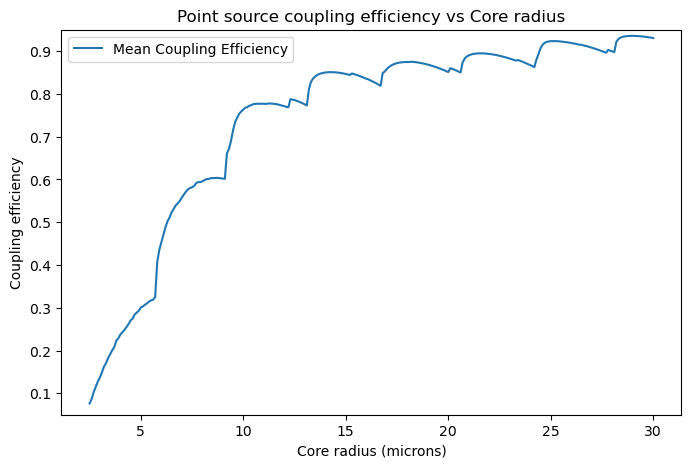

In [143]:
plt.figure(figsize=(8,5))
plt.plot(core_radius_range_full * 1e6, eta_mean_psf_core_acceptance, label="Mean Coupling Efficiency")
plt.ylim(0.05,0.95)
plt.xlabel('Core radius (microns)')
plt.ylabel('Coupling efficiency')
plt.title('Point source coupling efficiency vs Core radius')
plt.legend()

In [144]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0


def V_to_radius_um_axis(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6

In [145]:
V_to_radius_um_axis(2.405)

5.741514572040124

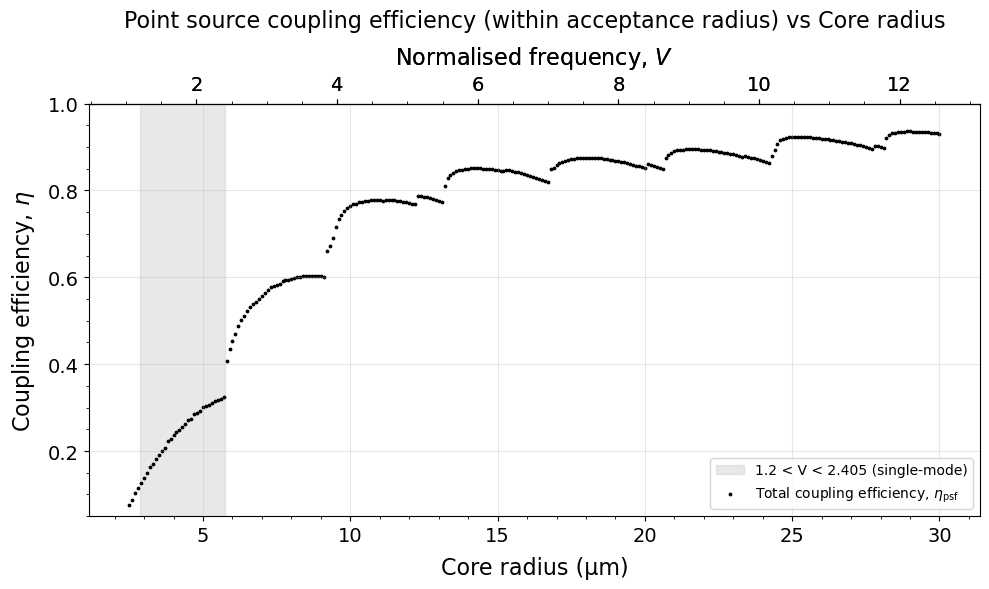

In [ ]:
plt.figure(figsize=(10, 6))
ax1 = plt.gca()

# Colour in 1.2 < V < 2.405 region in light grey
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label="1.2 < V < 2.405 (single-mode)"
)

ax1.scatter(
    core_radius_range_full * 1e6,
    eta_mean_psf_core_acceptance,
    label=r"Total coupling efficiency, $\eta_{\mathrm{psf}}$",
    color="black", s=3
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)


# -------------------------------------------------
# Top axis: normalised frequency V
# -------------------------------------------------


ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)

ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)
ax2.minorticks_on()

plt.ylim(0.05, 1.0)


plt.title("Point source coupling efficiency (within acceptance radius) vs Core radius", fontsize=16, pad=12)
plt.legend()

plt.tight_layout()
plt.show()


In [158]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_core = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core_LIGHT.joblib')
eta_bg_core = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index

In [161]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array = np.zeros_like(core_radius_range_full)
snr_array = np.zeros_like(core_radius_range_full)
signal_array = np.zeros_like(core_radius_range_full)
background_array = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal = eta_mean_psf_core_acceptance[i]
    background = eta_bg_core[i] * I_flat

    snr = signal / np.sqrt(Background_area * background) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array[i] = FOV
    snr_array[i] = snr
    signal_array[i] = signal
    background_array[i] = background

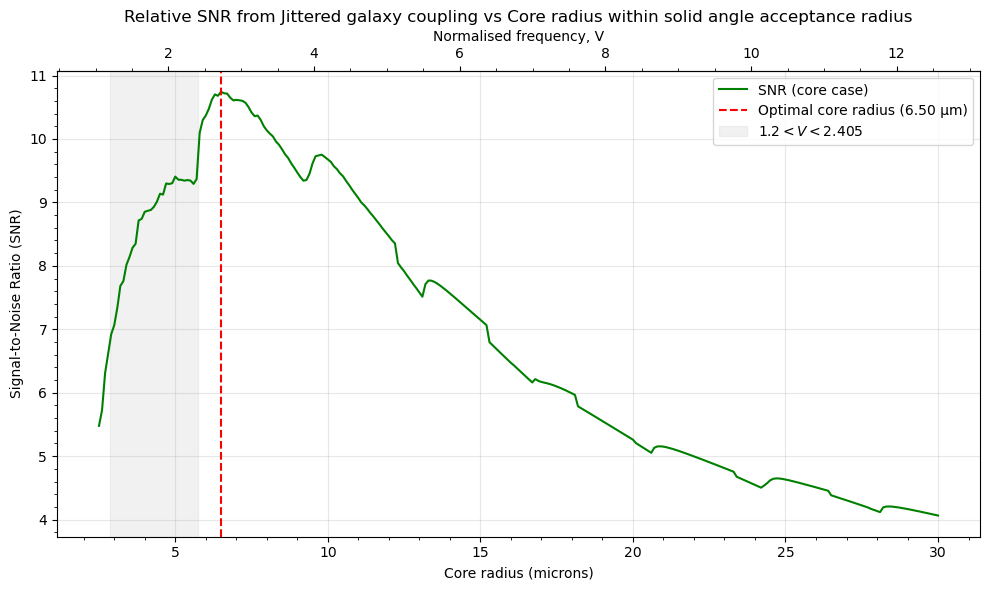

In [ ]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_range_full*1e6, snr_array, color='g', label='SNR (core case)')

ax1.axvline(core_radius_range_full[np.argmax(snr_array)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius within solid angle acceptance radius')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [182]:
core_radius_range_smf = core_radius_range_full[core_radius_range_full <= 5.7415e-6]

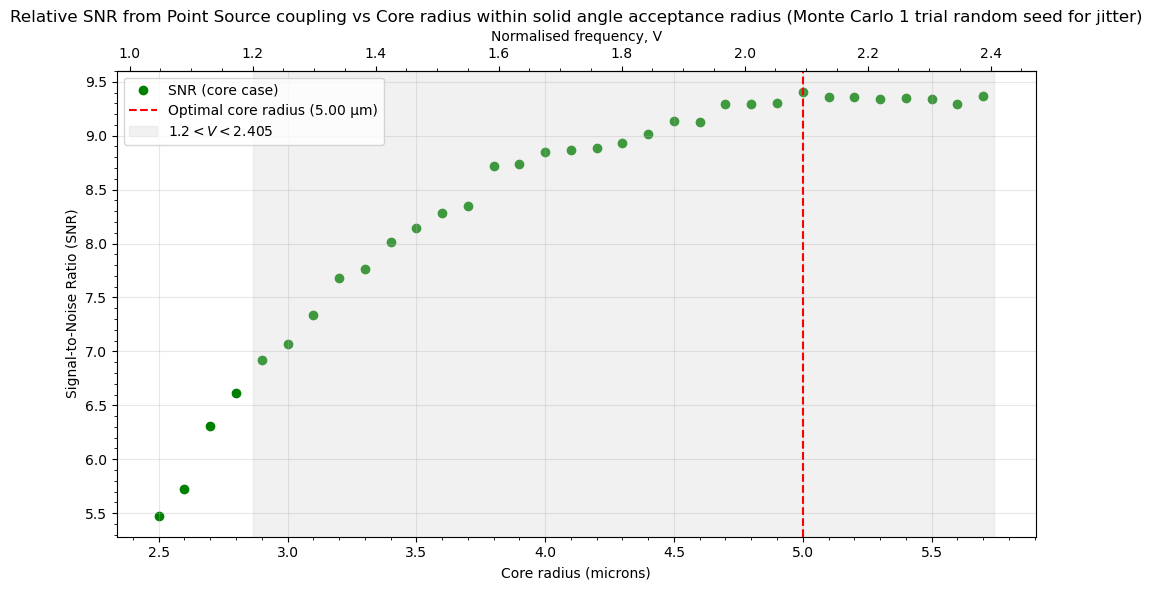

In [187]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_full[:len(core_radius_range_smf)]*1e6, snr_array[:len(core_radius_range_smf)], color='g', label='SNR (core case)')

ax1.axvline(core_radius_range_full[np.argmax(snr_array[:len(core_radius_range_smf)])] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array[:len(core_radius_range_smf)])] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Point Source coupling vs Core radius within solid angle acceptance radius (Monte Carlo 1 trial random seed for jitter)')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [147]:
eta_mean_psf_cladding, eta_std_psf_cladding, eta_standard_error_psf_cladding = jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_full, 
    eta_fixed_list=eta_tot_psf_radial_decentre_list, 
    decentre_array=decentre_array_cladding, 
    x=x, y=y, 
    x_1d=x_1d, y_1d=y_1d, 
    delta_x=delta_x, delta_y=delta_y, 
    # plate_scale_demag=plate_scale_demag,
    fibre_x=0.0, fibre_y=0.0,
    acceptance_radius=None,  # Use the fibre core radius as the acceptance radius
    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Batch computation too fast (0.0424959659576416s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Batch computation too fast (0.06538987159729004s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done  12 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  28 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Batch computation too fast (0.1283400058746338s.) Setting batch_size=8.
[Parallel(n_jobs=4)]: Done  56 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 128 tasks      | elapsed:    0.8s
[Parallel(n_jobs=4)]: Done 200 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Done 253 tasks      | elapsed:    1.4s
[Parallel(n_jobs=4)]: Done 264 tasks      | elapsed:    1.4s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    1.5s finished


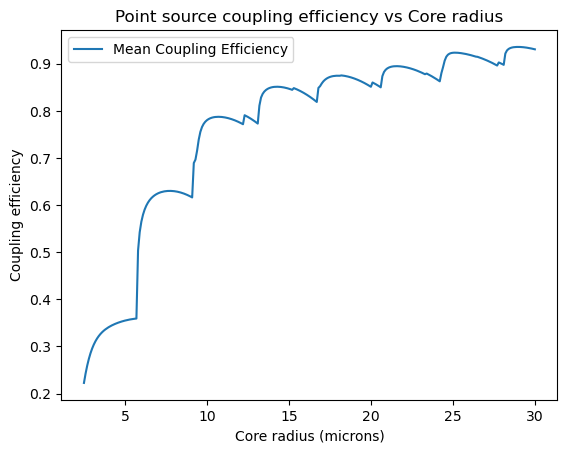

In [148]:
plt.plot(core_radius_range_full * 1e6, eta_mean_psf_cladding, label="Mean Coupling Efficiency")
plt.xlabel('Core radius (microns)')
plt.ylabel('Coupling efficiency')
plt.title('Point source coupling efficiency vs Core radius')
plt.legend()

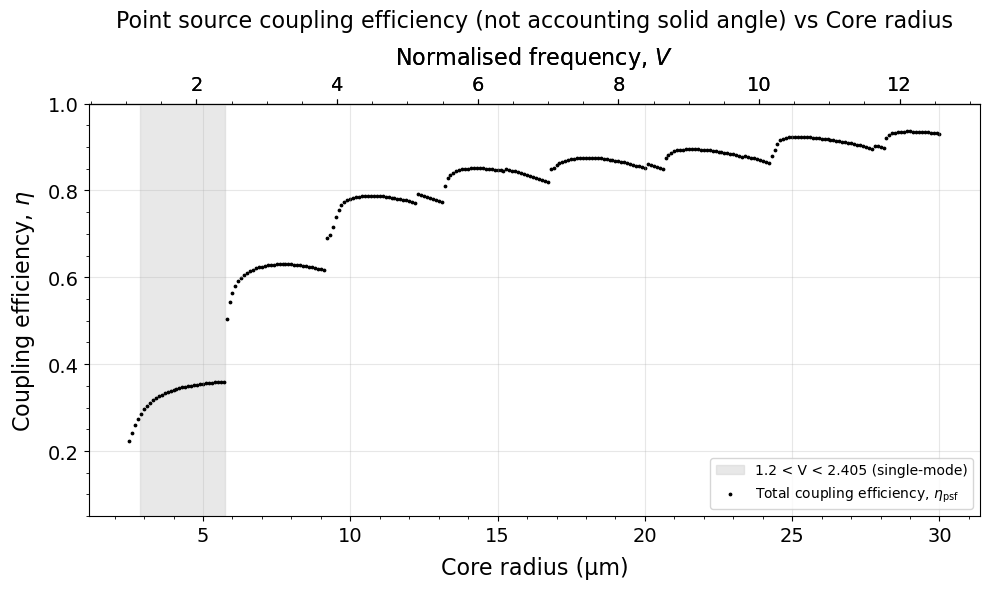

In [149]:
plt.figure(figsize=(10, 6))
ax1 = plt.gca()

# Colour in 1.2 < V < 2.405 region in light grey
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label="1.2 < V < 2.405 (single-mode)"
)

ax1.scatter(
    core_radius_range_full * 1e6,
    eta_mean_psf_cladding,
    label=r"Total coupling efficiency, $\eta_{\mathrm{psf}}$",
    color="black",
    s=3
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)


# -------------------------------------------------
# Top axis: normalised frequency V
# -------------------------------------------------


ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)

ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)
ax2.minorticks_on()

plt.ylim(0.05, 1.0)

plt.title("Point source coupling efficiency (not accounting solid angle) vs Core radius", fontsize=16, pad=12)
plt.legend()

plt.tight_layout()
plt.show()


In [167]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_clad = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_clad_LIGHT.joblib')
eta_bg_clad = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index

In [168]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array_cladding = np.zeros_like(core_radius_range_full)
snr_array_cladding = np.zeros_like(core_radius_range_full)
signal_array_cladding = np.zeros_like(core_radius_range_full)
background_array_cladding = np.zeros_like(core_radius_range_full)

for i, a in enumerate(core_radius_range_full): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_cladding = eta_mean_psf_cladding[i]
    background_cladding = eta_bg_clad[i] * I_flat

    snr_cladding = signal_cladding / np.sqrt(Background_area * background_cladding) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array_cladding[i] = FOV
    snr_array_cladding[i] = snr_cladding
    signal_array_cladding[i] = signal_cladding
    background_array_cladding[i] = background_cladding

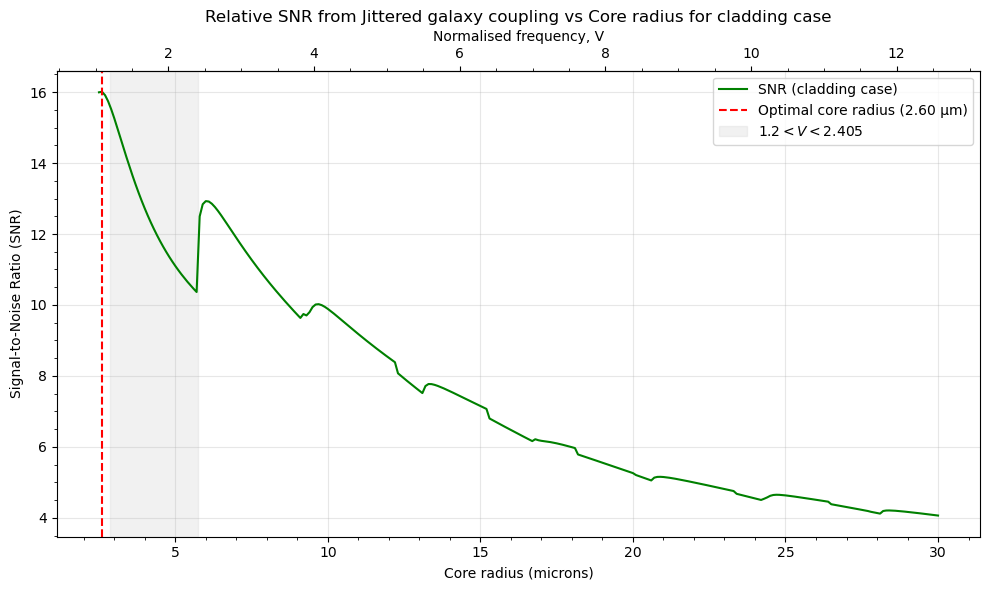

In [169]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(core_radius_range_full*1e6, snr_array_cladding, color='g', label='SNR (cladding case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius for cladding case')

ax1.axvline(core_radius_range_full[np.argmax(snr_array_cladding)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_full[np.argmax(snr_array_cladding)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius for cladding case')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [122]:
# Test the results using alternative method, 1D Reyleigh distribution of jittered point source coupling efficiency vs core radius

def rayleigh_pdf(radial_offset, sigma):
    """
    Rayleigh probability density for radial jitter.

    Parameters
    ----------
    radial_offset : array-like
        Radial displacement [m].

    sigma : float
        One-axis RMS jitter at the fibre plane [m].

    Returns
    -------
    pdf : ndarray
        Radial probability density [1/m].
    """ 

    # convert to numpy array
    radial_offset = np.asarray(radial_offset, dtype=float) 

    # Radial probablity density

    pdf = radial_offset / sigma**2 * np.exp(-radial_offset**2 / (2.0 * sigma**2))

    return pdf

In [ ]:
# def average_eta_over_rayleigh_jitter(
#         decentre_array,
#         eta_psf_array,
#         sigma_jitter,
#         acceptance_radius=None
# ): 
#     """
#     Average coupling efficiency over an isotropic jitter distribution. 

#     Parameters
#     ----------
#     decentre_array : 1D ndarray
#         Radial offsets used to calculate eta_psf_array [m].

#     eta_psf_array : 1D ndarray
#         Coupling efficiency at each radial offset.

#     sigma_jitter : float
#         One-axis RMS jitter at the fibre plane, in units of metres!!!

#     acceptance_radius : float or None
#         Radial acceptance boundary [m].
#         If None, the full calculated radial coupling response is used.

#     Returns 
#     -------
#     eta_mean: float
#         Mean coupling efficiency, averaged by the Rayleigh jitter distribution. 
    
#     probability_captured: float 
#         Probability that the PSF is contained within the finite offset range of decentre_array 
    
#     probability_density: n array
#         The Rayleigh probability density evaluated at decentre_array, used for weighting the average.

#     """

#     # Calculate the Rayleigh probability density at each radial offset
#     probability_density = rayleigh_pdf(
#         radial_offset=decentre_array,
#         sigma=sigma_jitter
#     )

#     # Make a copy of the coupling efficiency array
#     eta_psf_array_this = eta_psf_array.copy()

#     # Apply the acceptance radius if one is specified
#     if acceptance_radius is not None:

#         acceptance_mask = (
#             decentre_array <= acceptance_radius
#         )

#         eta_psf_array_this[~acceptance_mask] = 0.0

#     # The numerator of the weighted average is the integral of eta_psf_array * probability_density over decentre_array
#     eta_weighted = np.trapezoid(
#         eta_psf_array_this * probability_density,
#         x=decentre_array
#     ) 

#     # The denominator of the weighted average is the integral of the Rayleigh PDF over decentre_array
#     probability_captured = np.trapezoid(
#         probability_density,
#         x=decentre_array
#     )

#     # eta_mean is the weighted average normlalised by the total probability captured within the finite range of decentre_array
#     eta_mean = eta_weighted / probability_captured

#     return eta_mean, eta_weighted, probability_captured, probability_density

In [ ]:
def average_eta_over_rayleigh_jitter(
        decentre_array,
        eta_psf_array,
        sigma_jitter,
        acceptance_radius=None
): 
    """
    Average coupling efficiency over an isotropic jitter distribution. 

    Parameters
    ----------
    decentre_array : 1D ndarray
        Radial offsets used to calculate eta_psf_array [m].

    eta_psf_array : 1D ndarray
        Coupling efficiency at each radial offset.

    sigma_jitter : float
        One-axis RMS jitter at the fibre plane, in units of metres!!!

    acceptance_radius : float or None
        Radial acceptance boundary [m].
        If None, the full calculated radial coupling response is used.

    Returns 
    -------
    eta_mean: float
        Mean coupling efficiency, averaged by the Rayleigh jitter distribution. 
    
    probability_captured: float 
        Probability that the PSF is contained within the finite offset range of decentre_array 
    
    probability_density: n array
        The Rayleigh probability density evaluated at decentre_array, used for weighting the average.

    """

    # Apply the acceptance radius if one is specified
    if acceptance_radius is not None:

        # Interpolate the radial coupling efficiency so that the acceptance radius
        # can be included exactly as the final integration point.
        eta_interp = PchipInterpolator(
            decentre_array,
            eta_psf_array,
            extrapolate=False
        )

        # Select all calculated radial positions below the acceptance radius.
        inside_acceptance = (
            decentre_array < acceptance_radius
        )

        # Create the radial integration array and include the acceptance radius
        # exactly as the final integration point.
        decentre_array_adjusted = np.append(
            decentre_array[inside_acceptance],
            acceptance_radius
        )

        # Evaluate the coupling efficiency on the radial integration array. 
        # This is because if the resolution of decentre array is low, the exact
        # acceptance radius may fall between two calculated radial positions.
        # Interpolation allows the coupling efficiency to be evaluated at the exact
        # acceptance radius, preventing the integration boundary from jumping between
        # discrete radial grid points as the fibre core radius changes.
        eta_psf_array_this = eta_interp(
            decentre_array_adjusted
        )

    else:

        # Use the full calculated radial coupling response.
        decentre_array_adjusted = decentre_array
        eta_psf_array_this = eta_psf_array

    # Calculate the Rayleigh probability density at each radial offset
    probability_density = rayleigh_pdf(
        radial_offset=decentre_array_adjusted,
        sigma=sigma_jitter
    )

    # The numerator of the weighted average is the integral of eta_psf_array * probability_density over decentre_array
    eta_weighted = np.trapezoid(
        eta_psf_array_this * probability_density,
        x=decentre_array_adjusted
    ) 

    # The denominator of the weighted average is the integral of the Rayleigh PDF over the full calculated decentre range
    probability_density_full = rayleigh_pdf(
        radial_offset=decentre_array,
        sigma=sigma_jitter
    )

    probability_captured = np.trapezoid(
        probability_density_full,
        x=decentre_array
    )

    # eta_mean is the weighted average normlalised by the total probability captured within the finite range of decentre_array
    eta_mean = eta_weighted / probability_captured

    return eta_mean, eta_weighted, probability_captured, probability_density

In [ ]:
# Define function that calculates the mean coupling efficiency for each fibre core radius 
# using the Rayleigh distribution of jittered point source positions

def rayleigh_jittered_point_src_eta_vs_core_radius(
        core_radius_array, 
        eta_fixed_list, 
        decentre_array, 
        sigma_jitter_mas, 
        acceptance_radius="core_radius", 
        n_jobs=1, 
):
    """
    Calculate the mean coupling efficiency for each single-mode fibre core radius using the 
    Rayleigh distribution of jittered point source positions.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane. 
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_mas,
        focal_length=f_coude,
        demagnification=Magnification
    )

    # Check that there is one eta(r) array for every core radius. 
    if len(core_radius_array) != len(eta_fixed_list):
        raise ValueError(
            "core_radius_array and eta_fixed_list must have "
            "the same length."
        )

    # Define a function to calculate the mean coupling efficiency for a single core radius.
    def run_one_radius(core_radius, eta_fixed):

        # Determine the acceptance radius to use for the current fibre core radius.
        # If acceptance_radius="core_radius", the hard acceptance boundary changes
        # with each fibre in the core-radius sweep, so that light from a point source
        # jittered to a radial position greater than the current core radius is assigned
        # zero coupling efficiency.
        if acceptance_radius == "core_radius":
            acceptance_radius_adjusted = core_radius

        # Otherwise, use the acceptance radius supplied to the main function.
        # For example, if acceptance_radius=None, no additional hard acceptance
        # boundary is applied and the full calculated radial coupling response eta(r)
        # is averaged over the Rayleigh jitter distribution.
        else:
            acceptance_radius_adjusted = acceptance_radius

        # Average the radial point-source coupling efficiency eta(r) over the
        # Rayleigh probability distribution of radial jitter positions.
        #
        # When an acceptance radius is supplied, average_eta_over_rayleigh_jitter()
        # integrates the coupling response from r=0 to the exact acceptance radius.
        # Jitter positions outside this radius contribute zero coupling, but their
        # probability is still retained in the full Rayleigh distribution. Therefore,
        # the result represents the expected coupling efficiency over all possible
        # jitter positions, rather than the coupling conditional on the source
        # remaining inside the acceptance radius.
        eta_mean, eta_weighted, probability_captured, probability_density = average_eta_over_rayleigh_jitter(
            decentre_array=decentre_array,
            eta_psf_array=eta_fixed,
            sigma_jitter=sigma_jitter_metres,
            acceptance_radius=acceptance_radius_adjusted
        )

        return eta_mean

    if n_jobs == 1:

        results = [
            run_one_radius(core_radius, eta_fixed)
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        ]

    else:

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(run_one_radius)(
                core_radius,
                eta_fixed
            )
            for core_radius, eta_fixed in zip(
                core_radius_array,
                eta_fixed_list
            )
        )

    eta_mean = np.array(results)

    return eta_mean

In [190]:
core_radius_range_smf = core_radius_range_full[core_radius_range_full <= 5.7415e-6]
eta_fixed_list_smf = eta_tot_psf_radial_decentre_list[:len(core_radius_range_smf)]

In [191]:
eta_fixed_list_smf.shape

(33, 500)

In [192]:
eta_mean_psf_rayleigh_core_acceptance = rayleigh_jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_smf,
    eta_fixed_list=eta_fixed_list_smf,
    decentre_array=decentre_array_cladding,
    sigma_jitter_mas=20,
    acceptance_radius="core_radius",
    n_jobs=1
)

Text(0, 0.5, 'Coupling efficiency, $\\eta$')

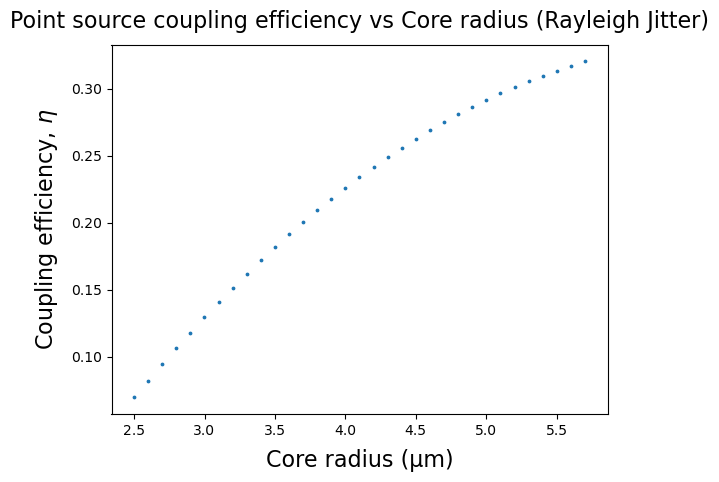

In [193]:
plt.scatter(core_radius_range_smf * 1e6, eta_mean_psf_rayleigh_core_acceptance, s=3, label="Mean Coupling Efficiency (Rayleigh Jitter)")
plt.title("Point source coupling efficiency vs Core radius (Rayleigh Jitter)", fontsize=16, pad=12)
plt.xlabel("Core radius (µm)", fontsize=16, labelpad=8)
plt.ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)
# plt.legend()

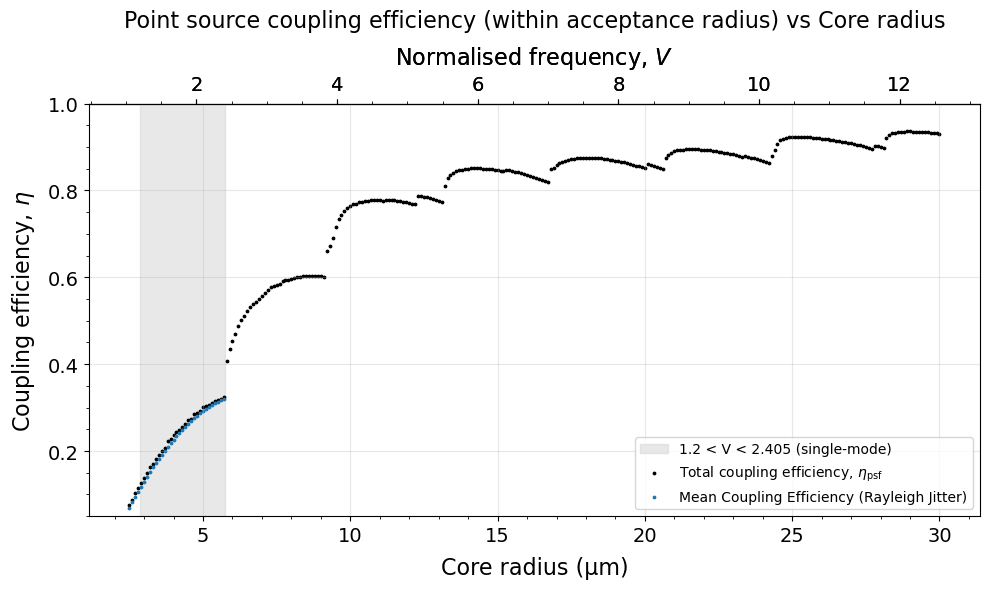

In [204]:
plt.figure(figsize=(10, 6))
ax1 = plt.gca()

# Colour in 1.2 < V < 2.405 region in light grey
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.5,
    label="1.2 < V < 2.405 (single-mode)"
)

ax1.scatter(
    core_radius_range_full * 1e6,
    eta_mean_psf_core_acceptance,
    label=r"Total coupling efficiency, $\eta_{\mathrm{psf}}$",
    color="black", s=3
)

ax1.set_xlabel("Core radius (µm)", fontsize=16, labelpad=8)
ax1.set_ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

ax1.tick_params(axis="x", labelsize=14)
ax1.tick_params(axis="y", labelsize=14)
ax1.minorticks_on()
ax1.grid(True, alpha=0.3)


# -------------------------------------------------
# Top axis: normalised frequency V
# -------------------------------------------------


ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)

ax2 = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax2.set_xlabel(
    r"Normalised frequency, $V$",
    fontsize=16,
    labelpad=8
)

ax2.tick_params(axis="x", labelsize=14)
ax2.minorticks_on()

plt.scatter(core_radius_range_smf * 1e6, eta_mean_psf_rayleigh_core_acceptance, s=3, label="Mean Coupling Efficiency (Rayleigh Jitter)")


plt.ylim(0.05, 1.0)


plt.title("Point source coupling efficiency (within acceptance radius) vs Core radius", fontsize=16, pad=12)
plt.legend()

plt.tight_layout()
plt.show()


In [194]:
# SNR for single-mode radius range using Rayleigh jittered point source coupling efficiency
I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_smf_array = np.zeros_like(core_radius_range_smf)
snr_smf_array = np.zeros_like(core_radius_range_smf)
signal_smf_array = np.zeros_like(core_radius_range_smf)
background_smf_array = np.zeros_like(core_radius_range_smf)

for i, a in enumerate(core_radius_range_smf):
    # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV_smf = plate_scale_demag * 2*a # in arcseconds
    FOV_smf_array[i] = FOV_smf

    # Background area coupled into the fibre
    Background_area_smf = np.pi * I_flat * (FOV_smf / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_smf = eta_mean_psf_rayleigh_core_acceptance[i]
    background_smf = eta_bg_core[i] * I_flat

    snr_smf = signal_smf / np.sqrt(Background_area_smf * background_smf) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_smf_array[i] = FOV_smf
    snr_smf_array[i] = snr_smf
    signal_smf_array[i] = signal_smf
    background_smf_array[i] = background_smf


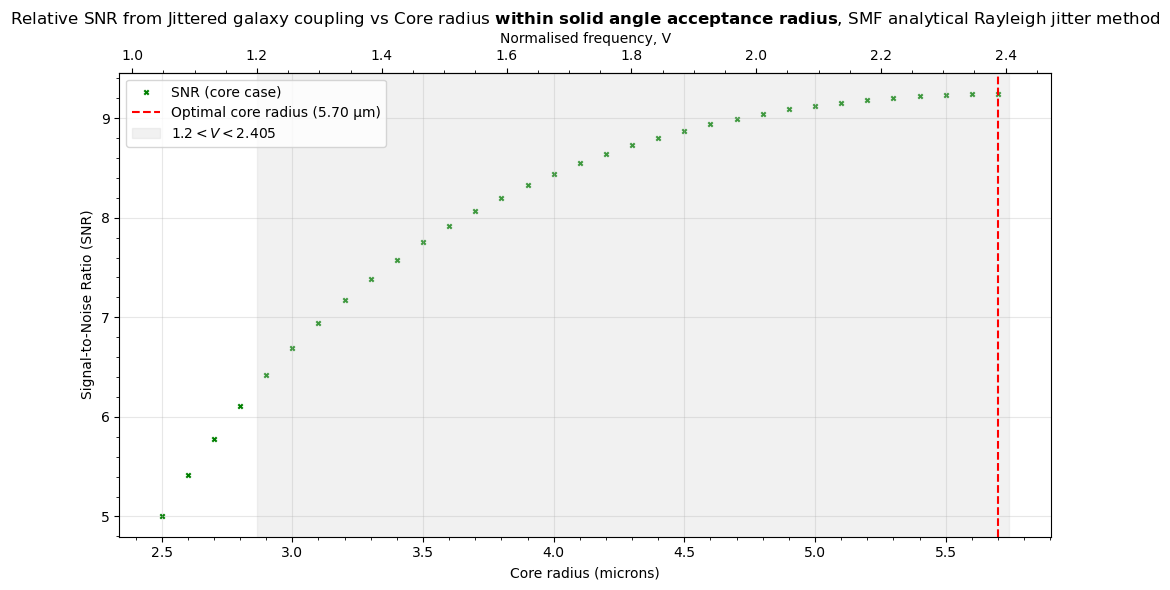

In [195]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_smf*1e6, snr_smf_array, color='g', s=10, marker='x', label='SNR (core case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius')

ax1.axvline(core_radius_range_smf[np.argmax(snr_smf_array)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_smf[np.argmax(snr_smf_array)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title(
    r'Relative SNR from Jittered galaxy coupling vs Core radius '
    r'$\mathbf{within\ solid\ angle\ acceptance\ radius}$, '
    r'SMF analytical Rayleigh jitter method'
)

ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [196]:
eta_mean_psf_rayleigh_core_acceptance / eta_mean_psf_core_acceptance[:len(core_radius_range_smf)]

array([0.91423614, 0.9455377 , 0.91603798, 0.92453992, 0.92698987,
       0.94726097, 0.94668214, 0.93391723, 0.95178918, 0.94547533,
       0.95283795, 0.95570916, 0.96631766, 0.9411642 , 0.95274073,
       0.95362514, 0.9637157 , 0.97298406, 0.97724403, 0.97708734,
       0.97145916, 0.9797004 , 0.96740255, 0.97343498, 0.97687462,
       0.96999147, 0.9783414 , 0.98151146, 0.98513139, 0.98595132,
       0.98820025, 0.99460979, 0.9869041 ])

In [197]:
eta_mean_psf_rayleigh_core_acceptance - eta_mean_psf_core_acceptance[:len(core_radius_range_smf)]

array([-0.00653867, -0.0047229 , -0.00863701, -0.00867501, -0.00930109,
       -0.0072147 , -0.00792769, -0.01072607, -0.00820912, -0.00993125,
       -0.00900878, -0.0088741 , -0.00699333, -0.01309402, -0.0108123 ,
       -0.01099888, -0.00881296, -0.0067101 , -0.00579712, -0.00600193,
       -0.00771612, -0.00557443, -0.00927084, -0.00766682, -0.00678117,
       -0.00902371, -0.0065666 , -0.00567507, -0.00461322, -0.00441361,
       -0.00374439, -0.00171874, -0.00425219])

In [198]:
eta_mean_psf_rayleigh_cladding = rayleigh_jittered_point_src_eta_vs_core_radius(
    core_radius_array=core_radius_range_smf,
    eta_fixed_list=eta_fixed_list_smf,
    decentre_array=decentre_array_cladding,
    sigma_jitter_mas=20,
    acceptance_radius=None,
    n_jobs=1
)

Text(0, 0.5, 'Coupling efficiency, $\\eta$')

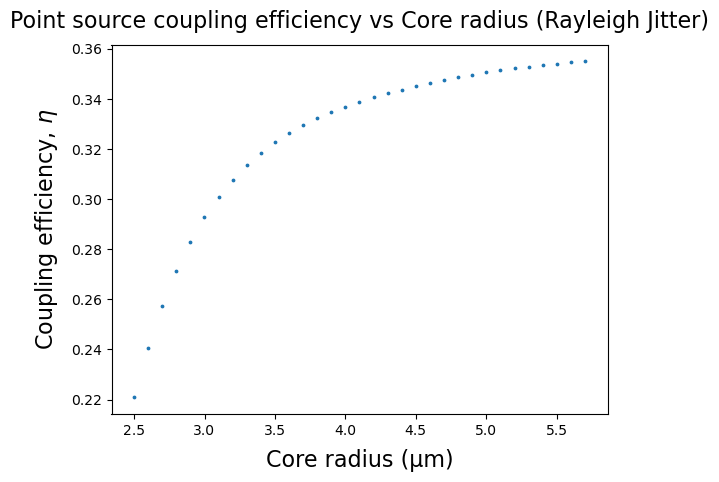

In [199]:
plt.scatter(core_radius_range_smf * 1e6, eta_mean_psf_rayleigh_cladding, s=3, label="Mean Coupling Efficiency (Rayleigh Jitter)")
plt.title("Point source coupling efficiency vs Core radius (Rayleigh Jitter)", fontsize=16, pad=12)
plt.xlabel("Core radius (µm)", fontsize=16, labelpad=8)
plt.ylabel(r"Coupling efficiency, $\eta$", fontsize=16, labelpad=8)

In [202]:
core_radius_range_smf

array([2.5e-06, 2.6e-06, 2.7e-06, 2.8e-06, 2.9e-06, 3.0e-06, 3.1e-06,
       3.2e-06, 3.3e-06, 3.4e-06, 3.5e-06, 3.6e-06, 3.7e-06, 3.8e-06,
       3.9e-06, 4.0e-06, 4.1e-06, 4.2e-06, 4.3e-06, 4.4e-06, 4.5e-06,
       4.6e-06, 4.7e-06, 4.8e-06, 4.9e-06, 5.0e-06, 5.1e-06, 5.2e-06,
       5.3e-06, 5.4e-06, 5.5e-06, 5.6e-06, 5.7e-06])

In [200]:
# SNR for single-mode radius range using Rayleigh jittered point source coupling efficiency
I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_smf_array_cladding = np.zeros_like(core_radius_range_smf)
snr_smf_array_cladding = np.zeros_like(core_radius_range_smf)
signal_smf_array_cladding = np.zeros_like(core_radius_range_smf)
background_smf_array_cladding = np.zeros_like(core_radius_range_smf)

for i, a in enumerate(core_radius_range_smf):
    # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV_smf = plate_scale_demag * 2*a # in arcseconds
    FOV_smf_array[i] = FOV_smf

    # Background area coupled into the fibre
    Background_area_smf = np.pi * I_flat * (FOV_smf / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal_smf_cladding = eta_mean_psf_rayleigh_cladding[i]
    background_smf_cladding = eta_bg_clad[i] * I_flat

    snr_smf_cladding = signal_smf_cladding / np.sqrt(Background_area_smf * background_smf_cladding) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_smf_array_cladding[i] = FOV_smf
    snr_smf_array_cladding[i] = snr_smf_cladding
    signal_smf_array_cladding[i] = signal_smf_cladding
    background_smf_array_cladding[i] = background_smf_cladding


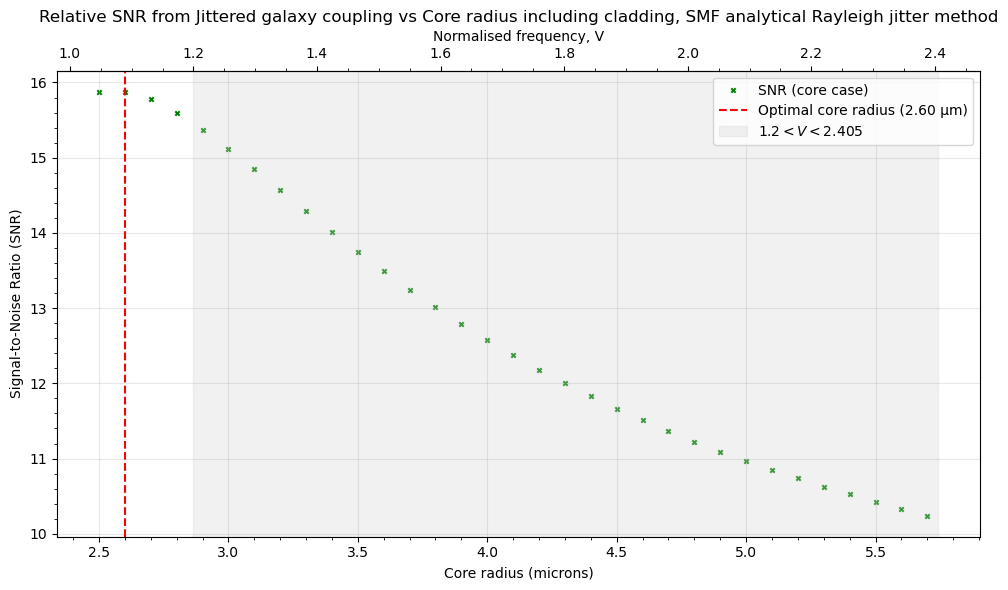

In [201]:
# Plot SNR vs Core radius

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.scatter(core_radius_range_smf*1e6, snr_smf_array_cladding, color='g', s=10, marker='x', label='SNR (core case)')
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('SNR vs Core radius')

ax1.axvline(core_radius_range_smf[np.argmax(snr_smf_array_cladding)] * 1e6, color='red', linestyle='dashed', label=f"Optimal core radius ({core_radius_range_smf[np.argmax(snr_smf_array_cladding)] * 1e6:.2f} µm)")
ax1.set_xlabel('Core radius (microns)')
ax1.set_ylabel('Signal-to-Noise Ratio (SNR)')
ax1.set_title('Relative SNR from Jittered galaxy coupling vs Core radius including cladding, SMF analytical Rayleigh jitter method')


ax1.minorticks_on()
ax1.grid(True, alpha=0.3)

# Add top x-axis for normalised frequency V
ax_top = ax1.secondary_xaxis(
    "top",
    functions=(radius_um_to_V, V_to_radius_um_axis)
)

ax_top.set_xlabel("Normalised frequency, V")
ax_top.minorticks_on()

# Shade single-mode region
V_1_2 = 1.2
V_2_405 = 2.405

ax1.axvspan(
    V_to_radius_um_axis(V_1_2),
    V_to_radius_um_axis(V_2_405),
    color="lightgrey",
    alpha=0.3,
    label=r"$1.2 < V < 2.405$"
)


ax1.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Rewrite the code and produce a coupling vs radius function that includes each mode to see behaviour of the coupling efficiency 
# in presence of jitter for each mode. 

In [205]:
def radial_displacement(
    x_displacement,
    y_displacement,
    misalignment=0.0,
    misalignment_angle=0.0
):
    """
    Calculate radial displacement including a fixed fibre misalignment.

    Parameters
    ----------
    x_displacement, y_displacement : float or array
        Random/source displacement in x and y.

    misalignment : float, optional
        Magnitude of the fixed fibre misalignment.

    misalignment_angle : float, optional
        Direction of the fixed misalignment in radians.

    Returns
    -------
    radial_displacement : float or array
        Total source-fibre radial separation.
    """

    x_misalignment = misalignment * np.cos(misalignment_angle)
    y_misalignment = misalignment * np.sin(misalignment_angle)

    x_total = x_displacement + x_misalignment
    y_total = y_displacement + y_misalignment

    return np.sqrt(x_total**2 + y_total**2)

In [ ]:
# def jittered_point_src_eta_per_mode_vs_core_radius(
#         core_radius_array, 
#         x, y,
#         x_1d, y_1d, 
#         delta_x, delta_y,
#         NA, lam0, 
#         F_eff, 
#         alpha, 
#         E_S=1.0,
#         acceptance_radius="core_radius", 
#         mode_case="few_mode", 
#         az_sym=False,
#         fibre_offset_x=0.0,
#         fibre_offset_y=0.0,
#         n_jobs=1,
# ):
#     """ 
#     Calculate the jitter-averaged point-source coupling efficiency for
#     each individual fibre mode as a function of fibre core radius.

#     The point-source position consists of:
#         1. a random jitter displacement (delta_x, delta_y), and
#         2. a fixed fibre misalignment (fibre_offset_x, fibre_offset_y).

#     Parameters
#     ----------
#     core_radius_array : array
#         Fibre core radii.

#     x, y : 2D arrays
#         Image-plane coordinate matrices [[n, m], [n, m], ...].
    
#     x_1d, y_1d : 1D arrays
#         1D image-plane coordinate grids.

#     delta_x, delta_y : 1D arrays
#         Monte Carlo jitter samples in x and y.

#     fibre_offset_x, fibre_offset_y : float, optional
#         Fixed displacement of the fibre centre relative to the nominal
#         source position.

#     """
#     # Store the results for every core radius.
#     results_all_radius = []

#     delta_x = np.asarray(delta_x)
#     delta_y = np.asarray(delta_y)

#     if delta_x.shape != delta_y.shape:
#         raise ValueError("delta_x and delta_y must have the same shape.")

#     n_samples = len(delta_x) # number of jittered point source positions

#     # ---------------------------------------------------------
#     # Effective source position relative to the actual fibre centre
#     # ---------------------------------------------------------
#     # Here fibre_offset_x/y describe where the fibre centre is relative to the nominal optical axis.
#     # Therefore, source relative to fibre = source position - fibre position
#     effective_delta_x = delta_x - fibre_offset_x
#     effective_delta_y = delta_y - fibre_offset_y

#     # Calculate this ONCE because it does not depend on core radius
#     radial_displacement = np.sqrt(effective_delta_x**2 + effective_delta_y**2)

#     # ---------------------------------------------------------
#     # Loop through fibre core radii
#     # ---------------------------------------------------------
#     for a in core_radius_array:

#         prepared_modes = prepare_modes_2d(
#             x,
#             y,
#             a=a,
#             NA=NA,
#             lam0=lam0,
#             az_sym=az_sym,
#             mode_case=mode_case,
#         )

#         # Acceptance radius for this fibre
#         if acceptance_radius == "core_radius":
#             acceptance_radius_adjusted = a
#         else:
#             acceptance_radius_adjusted = acceptance_radius

#         # Determine which jitterd point source positions are within the acceptance radius
#         if acceptance_radius_adjusted is not None:
#             inside_acceptance = radial_displacement <= acceptance_radius_adjusted
#         else:
#             inside_acceptance = np.ones_like(radial_displacement, dtype=bool)

#         # Store the total coupling efficiency for every jitter position.
#         # Positions outside the acceptance radius remain zero.
#         eta_samples_total = np.zeros(n_samples)

#         # Create one array of coupling efficiencies for every supported fibre mode.
#         # Each array has one value for every Monte Carlo jitter position.
#         eta_samples_modes = {}

#         for mode in prepared_modes:

#             # Create a label for the current fibre mode. 
#             if mode["l"] == 0:
#                 mode_label = f'LP0{mode["m"]}'
#             else:
#                 mode_label = (
#                     f'LP{mode["l"]}{mode["m"]} '
#                     f'{mode["angular"]}'
#                 )

#             # Initialise all jitter positions to zero coupling.
#             eta_samples_modes[mode_label] = np.zeros(n_samples)

#         # Calculate coupling efficiency only for point source positions that are within the acceptance radius.
#         for i in np.where(inside_acceptance)[0]:

#             eta_total, mode_results = total_eff_2d(
#                 prepared_modes=prepared_modes, 
#                 x=x, y=y,
#                 x_1d=x_1d, y_1d=y_1d,
#                 lam0=lam0, F_eff=F_eff, alpha=alpha, 
#                 decentre=(effective_delta_x[i], effective_delta_y[i]), 
#                 E_S=E_S
#             )

#         # Store the total coupling efficiency at this jitter position.
#             eta_samples_total[i] = eta_total

#             # Store the coupling efficiency of every individual mode
#             # at this jitter position.
#             for mode_result in mode_results:

#                 if mode_result["l"] == 0:
#                     mode_label = (
#                         f'LP0{mode_result["m"]}'
#                     )
#                 else:
#                     mode_label = (
#                         f'LP{mode_result["l"]}'
#                         f'{mode_result["m"]} '
#                         f'{mode_result["angular"]}'
#                     )

#                 eta_samples_modes[mode_label][i] = (
#                     mode_result["eta"]
#                 )

#         # Calculate the jitter-averaged total coupling efficiency for this fibre core radius.
#         eta_mean_total = np.mean(eta_samples_total)

#         # Calculate the jitter-averaged coupling efficiency for every individual fibre mode.
#         eta_mean_modes = {
#             mode_label: np.mean(eta_samples)
#             for mode_label, eta_samples in eta_samples_modes.items()
#         }

#         # Store the results for the current fibre core radius.
#         results_all_radius.append({
#             "core_radius": a,
#             "eta_total_mean": eta_mean_total,
#             "eta_total_samples": eta_samples_total,
#             "eta_mode_mean": eta_mean_modes,
#             "eta_mode_samples": eta_samples_modes,
#             "inside_acceptance": inside_acceptance,
#         })

#     return results_all_radius

In [229]:
def jittered_point_src_eta_per_mode_vs_core_radius(
        core_radius_array, 
        x, y,
        x_1d, y_1d, 
        delta_x, delta_y,
        NA, lam0, 
        F_eff, 
        alpha, 
        E_S=1.0,
        acceptance_radius="core_radius", 
        mode_case="few_mode", 
        az_sym=False,
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=1,
):
    """ 
    Calculate the jitter-averaged point-source coupling efficiency for
    each individual fibre mode as a function of fibre core radius.

    The point-source position consists of:
        1. a random jitter displacement (delta_x, delta_y), and
        2. a fixed fibre misalignment (fibre_offset_x, fibre_offset_y).

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii.

    x, y : 2D arrays
        Image-plane coordinate matrices [[n, m], [n, m], ...].
    
    x_1d, y_1d : 1D arrays
        1D image-plane coordinate grids.

    delta_x, delta_y : 1D arrays
        Monte Carlo jitter samples in x and y.

    fibre_offset_x, fibre_offset_y : float, optional
        Fixed displacement of the fibre centre relative to the nominal
        source position.

    """
    # Store the results for every core radius.
    # results_all_radius = []

    delta_x = np.asarray(delta_x)
    delta_y = np.asarray(delta_y)

    if delta_x.shape != delta_y.shape:
        raise ValueError("delta_x and delta_y must have the same shape.")

    n_samples = len(delta_x) # number of jittered point source positions

    # ---------------------------------------------------------
    # Effective source position relative to the actual fibre centre
    # ---------------------------------------------------------
    # Here fibre_offset_x/y describe where the fibre centre is relative to the nominal optical axis.
    # Therefore, source relative to fibre = source position - fibre position
    effective_delta_x = delta_x - fibre_offset_x
    effective_delta_y = delta_y - fibre_offset_y

    # Calculate this ONCE because it does not depend on core radius
    radial_displacement = np.sqrt(effective_delta_x**2 + effective_delta_y**2)

    # ---------------------------------------------------------
    # Loop through fibre core radii
    # ---------------------------------------------------------
    # for a in core_radius_array:

    # ---------------------------------------------------------
    # Calculate the coupling efficiency for one fibre core radius.
    # This function will be run in parallel for different core radii.
    # ---------------------------------------------------------
    def run_one_radius(a):

        prepared_modes = prepare_modes_2d(
            x,
            y,
            a=a,
            NA=NA,
            lam0=lam0,
            az_sym=az_sym,
            mode_case=mode_case,
        )

        # Acceptance radius for this fibre
        if acceptance_radius == "core_radius":
            acceptance_radius_adjusted = a
        else:
            acceptance_radius_adjusted = acceptance_radius

        # Determine which jitterd point source positions are within the acceptance radius
        if acceptance_radius_adjusted is not None:
            inside_acceptance = radial_displacement <= acceptance_radius_adjusted
        else:
            inside_acceptance = np.ones_like(radial_displacement, dtype=bool)

        # Store the total coupling efficiency for every jitter position.
        # Positions outside the acceptance radius remain zero.
        eta_samples_total = np.zeros(n_samples)

        # Create one array of coupling efficiencies for every supported fibre mode.
        # Each array has one value for every Monte Carlo jitter position.
        eta_samples_modes = {}

        for mode in prepared_modes:

            # Create a label for the current fibre mode. 
            if mode["l"] == 0:
                mode_label = f'LP0{mode["m"]}'
            else:
                mode_label = (
                    f'LP{mode["l"]}{mode["m"]} '
                    f'{mode["angular"]}'
                )

            # Initialise all jitter positions to zero coupling.
            eta_samples_modes[mode_label] = np.zeros(n_samples)

        # Calculate coupling efficiency only for point source positions that are within the acceptance radius.
        for i in np.where(inside_acceptance)[0]:

            eta_total, mode_results = total_eff_2d(
                prepared_modes=prepared_modes, 
                x=x, y=y,
                x_1d=x_1d, y_1d=y_1d,
                lam0=lam0, F_eff=F_eff, alpha=alpha, 
                decentre=(effective_delta_x[i], effective_delta_y[i]), 
                E_S=E_S
            )

        # Store the total coupling efficiency at this jitter position.
            eta_samples_total[i] = eta_total

            # Store the coupling efficiency of every individual mode
            # at this jitter position.
            for mode_result in mode_results:

                if mode_result["l"] == 0:
                    mode_label = (
                        f'LP0{mode_result["m"]}'
                    )
                else:
                    mode_label = (
                        f'LP{mode_result["l"]}'
                        f'{mode_result["m"]} '
                        f'{mode_result["angular"]}'
                    )

                eta_samples_modes[mode_label][i] = (
                    mode_result["eta"]
                )

        # Calculate the jitter-averaged total coupling efficiency for this fibre core radius.
        eta_mean_total = np.mean(eta_samples_total)

        # Calculate the jitter-averaged coupling efficiency for every individual fibre mode.
        eta_mean_modes = {
            mode_label: np.mean(eta_samples)
            for mode_label, eta_samples in eta_samples_modes.items()
        }

        # Store the results for the current fibre core radius.
        # results_all_radius.append({
        #     "core_radius": a,
        #     "eta_total_mean": eta_mean_total,
        #     "eta_total_samples": eta_samples_total,
        #     "eta_mode_mean": eta_mean_modes,
        #     "eta_mode_samples": eta_samples_modes,
        #     "inside_acceptance": inside_acceptance,
        # })

        # Return the results for the current fibre core radius.
        return {
            "core_radius": a,
            "eta_total_mean": eta_mean_total,
            "eta_total_samples": eta_samples_total,
            "eta_mode_mean": eta_mean_modes,
            "eta_mode_samples": eta_samples_modes,
            "inside_acceptance": inside_acceptance,
        }

    # ---------------------------------------------------------
    # Parallel processing over fibre core radius
    # ---------------------------------------------------------
    if n_jobs == 1:

        results_all_radius = [
            run_one_radius(a)
            for a in core_radius_array
        ]

    else:

        results_all_radius = Parallel(
            n_jobs=n_jobs,
            verbose=10
        )(
            delayed(run_one_radius)(a)
            for a in core_radius_array
        )

    return results_all_radius

In [212]:
# total_eff_2d?

In [211]:
# x, y

In [210]:
# np.meshgrid?

In [215]:
delta_x.shape

(1000,)

In [218]:
delta_x_300, delta_y_300 = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=300,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [219]:
core_radius_test = np.array([25e-6])

results_test = jittered_point_src_eta_per_mode_vs_core_radius(
    core_radius_array=core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x_300,
    delta_y=delta_y_300,
    NA=NA,
    lam0=lam0,
    F_eff=F_fibre,
    alpha=alpha_vlt,
    E_S=1.0,
    acceptance_radius="core_radius",
    mode_case="few_mode",
    az_sym=False,
    fibre_offset_x=0.0,
    fibre_offset_y=0.0,
)

In [228]:
core_radius_range_full.shape

(276,)

In [226]:
results_test = jittered_point_src_eta_per_mode_vs_core_radius(
    core_radius_array=core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x_300,
    delta_y=delta_y_300,
    NA=NA,
    lam0=lam0,
    F_eff=F_fibre,
    alpha=alpha_vlt,
    E_S=1.0,
    acceptance_radius="core_radius",
    mode_case="few_mode",
    az_sym=False,
    fibre_offset_x=0.0,
    fibre_offset_y=0.0,
    n_jobs=4,
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    3.5s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    4.3s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    5.8s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    6.6s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    8.8s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   10.4s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   12.7s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   14.4s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   17.5s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   19.9s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   23.5s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:   26.3s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:   29.8s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:   32.9s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:   36.6s
[Parallel(

In [236]:
results_test

[{'core_radius': np.float64(2.5e-05),
  'eta_total_mean': np.float64(0.9237064062150887),
  'eta_total_samples': array([0.9166195 , 0.91475265, 0.92614358, 0.9279428 , 0.91278118,
         0.91810242, 0.93398209, 0.92351456, 0.93226318, 0.91322175,
         0.9215543 , 0.92912609, 0.91677984, 0.92528693, 0.92847392,
         0.92894581, 0.93387676, 0.92561002, 0.92374256, 0.9256764 ,
         0.9300938 , 0.93109002, 0.91777065, 0.93048485, 0.91439686,
         0.93001858, 0.91835054, 0.93389717, 0.92484688, 0.9314179 ,
         0.9012173 , 0.93059691, 0.9294219 , 0.92407016, 0.93195546,
         0.91836956, 0.93134929, 0.92908967, 0.92232953, 0.92915244,
         0.90425255, 0.93190378, 0.93145926, 0.93316766, 0.91902969,
         0.9103487 , 0.92727267, 0.93181774, 0.91724386, 0.92140375,
         0.93321622, 0.92723645, 0.91999101, 0.92933328, 0.92584033,
         0.93135753, 0.93396111, 0.92073791, 0.92512447, 0.92813666,
         0.91779889, 0.93289416, 0.92774237, 0.92528757, 0.93

In [231]:
print("Core radius:")
print(results_test[0]["core_radius"] * 1e6, "µm")

print("\nTotal mean coupling:")
print(results_test[0]["eta_total_mean"])

print("\nNumber of accepted jitter positions:")
print(np.sum(results_test[0]["inside_acceptance"]))

print("\nNumber of MC samples:")
print(len(results_test[0]["eta_total_samples"]))

Core radius:
25.0 µm

Total mean coupling:
0.9237064062150887

Number of accepted jitter positions:
300

Number of MC samples:
300


In [232]:
print("\nModes:")
print(results_test[0]["eta_mode_mean"].keys())


Modes:
dict_keys(['LP01', 'LP11 cos', 'LP11 sin', 'LP02', 'LP21 cos', 'LP21 sin', 'LP31 cos', 'LP31 sin', 'LP12 cos', 'LP12 sin', 'LP41 cos', 'LP41 sin', 'LP03', 'LP22 cos', 'LP22 sin', 'LP51 cos', 'LP51 sin', 'LP32 cos', 'LP32 sin', 'LP13 cos', 'LP13 sin', 'LP42 cos', 'LP42 sin', 'LP04', 'LP23 cos', 'LP23 sin'])


In [233]:
for mode_label, eta_mean in results_test[0]["eta_mode_mean"].items():
    print(
        f"{mode_label}: "
        f"mean eta = {eta_mean:.6f}"
    )

LP01: mean eta = 0.063291
LP11 cos: mean eta = 0.017024
LP11 sin: mean eta = 0.020380
LP02: mean eta = 0.180125
LP21 cos: mean eta = 0.004544
LP21 sin: mean eta = 0.004207
LP31 cos: mean eta = 0.001561
LP31 sin: mean eta = 0.001533
LP12 cos: mean eta = 0.067186
LP12 sin: mean eta = 0.079525
LP41 cos: mean eta = 0.000658
LP41 sin: mean eta = 0.000751
LP03: mean eta = 0.151005
LP22 cos: mean eta = 0.034436
LP22 sin: mean eta = 0.028587
LP51 cos: mean eta = 0.000231
LP51 sin: mean eta = 0.000269
LP32 cos: mean eta = 0.009646
LP32 sin: mean eta = 0.010023
LP13 cos: mean eta = 0.076214
LP13 sin: mean eta = 0.086948
LP42 cos: mean eta = 0.001661
LP42 sin: mean eta = 0.001950
LP04: mean eta = 0.050156
LP23 cos: mean eta = 0.017525
LP23 sin: mean eta = 0.014270


In [230]:
results_jitter_per_mode_full = jittered_point_src_eta_per_mode_vs_core_radius(
    core_radius_array=core_radius_range_full,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    delta_x=delta_x_300,
    delta_y=delta_y_300,
    NA=NA,
    lam0=lam0,
    F_eff=F_fibre,
    alpha=alpha_vlt,
    E_S=1.0,
    acceptance_radius="core_radius",
    mode_case="few_mode",
    az_sym=False,
    fibre_offset_x=0.0,
    fibre_offset_y=0.0,
    n_jobs=4,
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   12.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   18.5s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   32.4s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   46.7s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  2.3min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:  3.5min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:  5.0min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:  8.1min
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed: 11.3min
/Users/tliu/.conda/envs/oh_suppression_env/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=4)]: Done 105 task

In [235]:
import sys

# Size of the list itself.
list_size = sys.getsizeof(results_jitter_per_mode_full)

# Size of all NumPy arrays stored inside the list.
array_size = 0

for result in results_jitter_per_mode_full:

    # Total coupling efficiency samples.
    array_size += result["eta_total_samples"].nbytes

    # Coupling efficiency samples for every individual mode.
    for eta_samples in result["eta_mode_samples"].values():
        array_size += eta_samples.nbytes

    # Boolean acceptance mask.
    array_size += result["inside_acceptance"].nbytes

total_size = list_size + array_size

print(f"RAM used by result: {total_size / 1024**2:.2f} MB")
print(f"RAM used by result: {total_size / 1024**3:.3f} GB")

RAM used by result: 9.56 MB
RAM used by result: 0.009 GB


In [237]:
from pathlib import Path
import joblib


# ---------------------------------------------------------
# Create checkpoint directory
# ---------------------------------------------------------
checkpoint_dir = Path(
    "/Users/tliu/oh_suppression/result/Point_source_jitter_per_mode"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ---------------------------------------------------------
# Define checkpoint file
# ---------------------------------------------------------
checkpoint_file = (
    checkpoint_dir /
    "results_jitter_per_mode_full.joblib"
)


# ---------------------------------------------------------
# Save results and calculation parameters
# ---------------------------------------------------------
checkpoint = {
    # Main results
    "results_jitter_per_mode_full":
        results_jitter_per_mode_full,

    # Fibre core radius range
    "core_radius_array":
        core_radius_range_full,

    # Monte Carlo jitter positions
    "delta_x":
        delta_x_300,

    "delta_y":
        delta_y_300,

    # Optical parameters
    "NA":
        NA,

    "lam0":
        lam0,

    "F_eff":
        F_fibre,

    "alpha":
        alpha_vlt,

    "E_S":
        1.0,

    # Coupling model settings
    "acceptance_radius":
        "core_radius",

    "mode_case":
        "few_mode",

    "az_sym":
        False,

    # Fixed fibre alignment
    "fibre_offset_x":
        0.0,

    "fibre_offset_y":
        0.0,

    # Monte Carlo information
    "n_jitter_samples":
        len(delta_x_300),
}


joblib.dump(
    checkpoint,
    checkpoint_file
)

print(
    f"Checkpoint saved to:\n{checkpoint_file}"
)

Checkpoint saved to:
/Users/tliu/oh_suppression/result/Point_source_jitter_per_mode/results_jitter_per_mode_full.joblib


In [ ]:
# from pathlib import Path
# import joblib


# checkpoint_file = Path(
#     "/Users/tliu/oh_suppression/result/Point_source_jitter_per_mode/"
#     "results_jitter_per_mode_full.joblib"
# )

# checkpoint = joblib.load(
#     checkpoint_file
# )


# # ---------------------------------------------------------
# # Recover main results
# # ---------------------------------------------------------
# results_jitter_per_mode_full = (
#     checkpoint["results_jitter_per_mode_full"]
# )

# core_radius_range_full = (
#     checkpoint["core_radius_array"]
# )

# delta_x_300 = checkpoint["delta_x"]
# delta_y_300 = checkpoint["delta_y"]


# print(
#     f"Loaded {len(results_jitter_per_mode_full)} "
#     f"core-radius results."
# )

In [238]:
def plot_jittered_point_source_efficiency_asymmetric_modes(
    core_radius_array,
    results,
    title="Jitter-averaged point-source coupling efficiency of asymmetric LP modes",
):
    """
    Plot total jitter-averaged point-source coupling efficiency
    and asymmetric LP modes only.

    Asymmetric modes are identified from labels containing:
        " cos"
        " sin"

    The cos/sin pair for each base LP mode shares the same colour.
    """

    # Extract the total jitter-averaged coupling efficiency.
    eta_total_mean = np.array([
        result["eta_total_mean"]
        for result in results
    ])

    # Find all mode labels present in the results.
    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result["eta_mode_mean"].keys()
        )
    )

    # Keep only asymmetric modes.
    asymmetric_mode_labels = [
        label
        for label in all_mode_labels
        if (" cos" in label) or (" sin" in label)
    ]

    # Store the coupling efficiency of each asymmetric mode
    # as a function of fibre core radius.
    asymmetric_mode_eta_dict = {}

    for mode_label in asymmetric_mode_labels:

        asymmetric_mode_eta_dict[mode_label] = np.array([
            result["eta_mode_mean"].get(mode_label, 0.0)
            for result in results
        ])

    # Base mode names: LP11, LP21, LP31, ...
    base_modes = sorted(
        set(
            label.split()[0]
            for label in asymmetric_mode_eta_dict.keys()
        )
    )

    # One colour per base LP mode.
    cmap = plt.cm.turbo
    colours = cmap(
        np.linspace(0, 1, len(base_modes))
    )

    colour_dict = {
        base_mode: colours[i]
        for i, base_mode in enumerate(base_modes)
    }

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total jitter-averaged point-source coupling efficiency.
    ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        linewidth=2,
        label=r"Total jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$"
    )

    # Shade single-mode region.
    V_1_2 = 1.2
    V_2_405 = 2.405

    ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # Plot asymmetric modes.
    mode_lines = {}

    for base_mode in base_modes:

        cos_label = f"{base_mode} cos"
        sin_label = f"{base_mode} sin"

        colour = colour_dict[base_mode]

        if cos_label in asymmetric_mode_eta_dict:
            line_cos, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[cos_label],
                linestyle="dashed",
                linewidth=1.5,
                alpha=0.9,
                color=colour,
                label=cos_label
            )

            mode_lines[cos_label] = line_cos

        if sin_label in asymmetric_mode_eta_dict:
            line_sin, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[sin_label],
                linestyle="dotted",
                linewidth=1.8,
                alpha=0.9,
                color=colour,
                label=sin_label
            )

            mode_lines[sin_label] = line_sin

    # Axis labels.
    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$",
        fontsize=16,
        labelpad=8
    )

    # ax1.set_title(title, fontsize=15)

    ax1.tick_params(axis="x", labelsize=14)
    ax1.tick_params(axis="y", labelsize=14)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top x-axis: normalised frequency V.
    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(axis="x", labelsize=14)
    ax_top.minorticks_on()

    # Legend.
    handles, labels = ax1.get_legend_handles_labels()

    n_legend_rows = 4
    n_legend_cols = math.ceil(
        len(labels) / n_legend_rows
    )

    ax1.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
        bbox_transform=ax1.transAxes,
        ncol=n_legend_cols,
        mode="expand",
        fontsize=8,
        frameon=True,
        columnspacing=0.8,
        handlelength=1.6,
        handletextpad=0.4,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()

    return asymmetric_mode_eta_dict, mode_lines

In [240]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


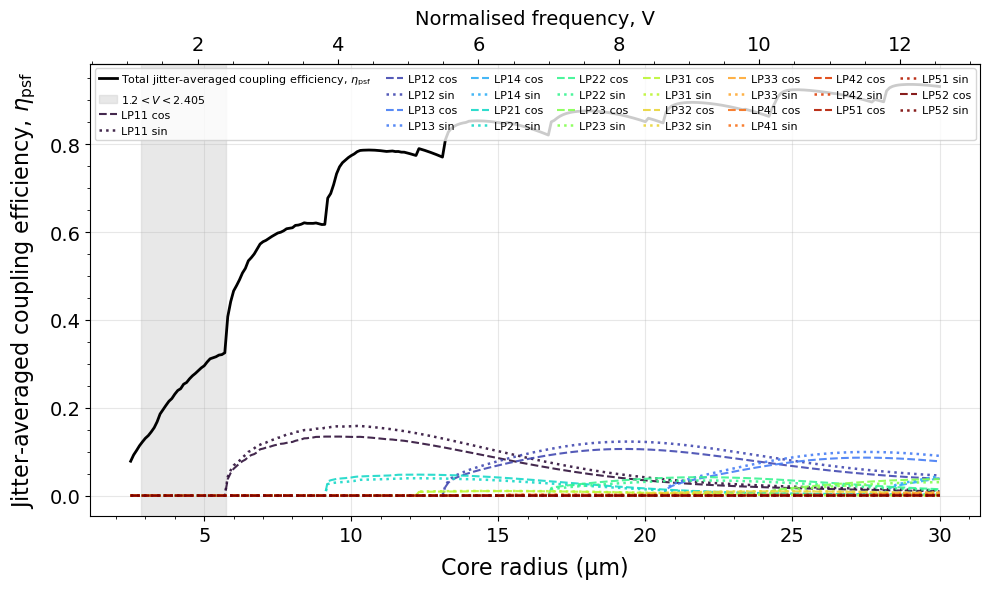

In [243]:
asymmetric_mode_eta_dict, mode_lines = (
    plot_jittered_point_source_efficiency_asymmetric_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
    )
)

In [250]:
def plot_jittered_point_source_efficiency_l0_modes(
    core_radius_array,
    results,
    # title="Jitter-averaged point-source coupling efficiency vs Core radius",
    total_label=r"Total jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$",
    total_color="k",
):
    """
    Plot jitter-averaged point-source coupling efficiency with
    LP01, LP02, LP03, LP04 shown as dashed lines.
    """

    # Extract the total jitter-averaged coupling efficiency.
    eta_total_mean = np.array([
        result["eta_total_mean"]
        for result in results
    ])

    # Extract the jitter-averaged coupling efficiency of the l=0 modes.
    mode_eta_dict = {}

    for mode_label in ["LP01", "LP02", "LP03", "LP04"]:

        mode_eta_dict[mode_label] = np.array([
            result["eta_mode_mean"].get(mode_label, 0.0)
            for result in results
        ])

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total jitter-averaged point-source coupling efficiency
    ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color=total_color,
        linewidth=2,
        label=total_label
    )

    # Shade single-mode region
    V_1_2 = 1.2
    V_2_405 = 2.405

    ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # LP01, LP02, LP03, LP04 dashed lines
    line_LP01, = ax1.plot(
        core_radius_array * 1e6,
        mode_eta_dict["LP01"],
        linestyle="dashed",
        linewidth=1.8,
        label="LP01"
    )

    line_LP02, = ax1.plot(
        core_radius_array * 1e6,
        mode_eta_dict["LP02"],
        linestyle="dashed",
        linewidth=1.8,
        label="LP02"
    )

    line_LP03, = ax1.plot(
        core_radius_array * 1e6,
        mode_eta_dict["LP03"],
        linestyle="dashed",
        linewidth=1.8,
        label="LP03"
    )

    line_LP04, = ax1.plot(
        core_radius_array * 1e6,
        mode_eta_dict["LP04"],
        linestyle="dashed",
        linewidth=1.8,
        label="LP04"
    )

    # Axis labels
    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=14,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$",
        fontsize=14,
        labelpad=8
    )

    # ax1.set_title(
    #     title,
    #     fontsize=18,
    #     pad=15
    # )

    ax1.tick_params(axis="x", labelsize=12)
    ax1.tick_params(axis="y", labelsize=12)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top x-axis: normalised frequency V
    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(
        axis="x",
        labelsize=14
    )

    ax_top.minorticks_on()

    # Legend inside plot at the top
    ax1.legend(
        loc="upper left",
        fontsize=9,
        frameon=True,
        framealpha=0.85,
        ncol=3
    )

    plt.tight_layout()
    plt.show()

    mode_lines = {
        "LP01": line_LP01,
        "LP02": line_LP02,
        "LP03": line_LP03,
        "LP04": line_LP04,
    }

    return mode_eta_dict, mode_lines

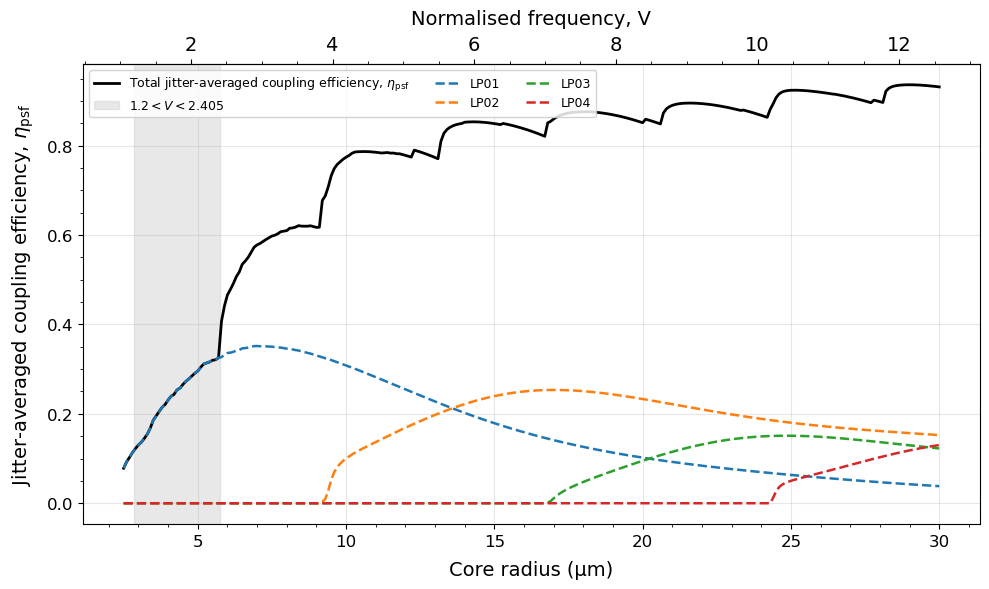

In [251]:
mode_eta_dict, mode_lines = (
    plot_jittered_point_source_efficiency_l0_modes(
        core_radius_array=core_radius_range_full,
        results=results_jitter_per_mode_full,
    )
)